# Tutorial 1: Bimodal Tactile Sensor Physics (6D Hall Array vs. GelSight VBT)

This notebook demonstrates the unified physical forward simulation of:
1. **6D Hall-Effect Magnetoelectric Tactile Array** (PaXini ITPU architecture): force-conserving Gaussian elastic scatter, nonlinear magnetic dipole flux, inverse calibration coupling, and 50–300 Hz stick-slip micro-vibrations.
2. **Vision-Based Tactile Sensor (VBT / GelSight)**: orthographic depth penetration, 2D-FFT Screened Poisson membrane draping, Taxim polynomial photometric shading, and Boussinesq-Cerruti marker optical flow.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bimodal_tactile.sensors import Hall6DArraySimulator, VBTOpticalSimulator

# Create a 6x6 fingerpad 6D Hall array (20mm x 20mm)
gx, gy = np.meshgrid(np.linspace(-0.008, 0.008, 6), np.linspace(-0.008, 0.008, 6))
taxel_pos = np.stack([gx.ravel(), gy.ravel(), np.zeros(36)], axis=-1)
hall_sim = Hall6DArraySimulator(taxel_pos, link_ids=np.ones(36, dtype=np.int32))
vbt_sim = VBTOpticalSimulator()
print(f'Initialized {hall_sim.n_taxels} 6D Hall taxels and {vbt_sim.H}x{vbt_sim.W} VBT sensor.')

Initialized 36 6D Hall taxels and 64x64 VBT sensor.


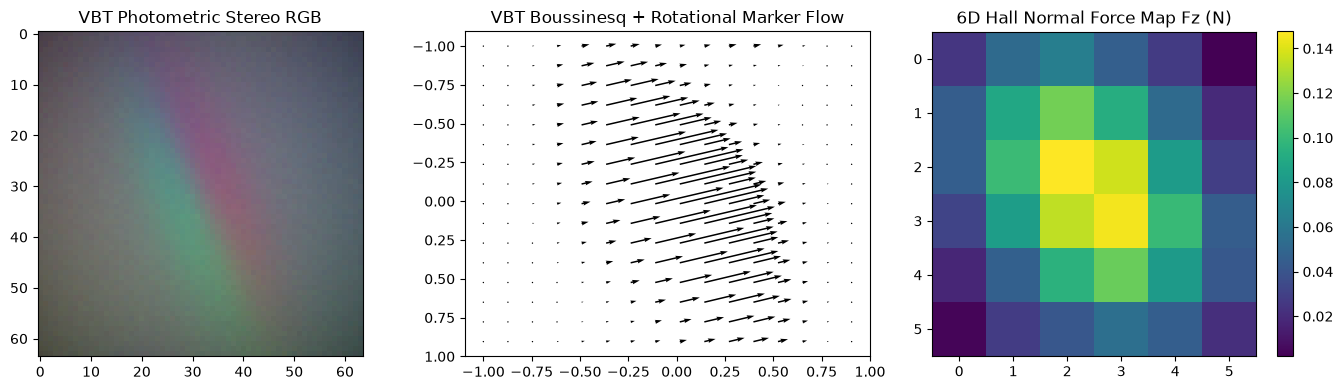

In [2]:
# Simulate an object with a raised diagonal ridge pressing into the fingerpad
yy, xx = np.meshgrid(np.linspace(-1, 1, 64), np.linspace(-1, 1, 64), indexing='ij')
ridge_indent = 0.0016 * np.exp(-((xx - 0.4 * yy) ** 2) / 0.035) * np.exp(-(yy ** 2) / 0.5)
depth_buffer = vbt_sim.cfg.z_far_m - ridge_indent

vbt_out = vbt_sim.render(depth_buffer, tangential_force_xy=(0.85, 0.20), torsional_torque_z=0.006)

# Corresponding contact forces mapped onto the 6x6 6D Hall array
contact_pos = np.array([[-0.002, -0.003, 0.0], [0.002, 0.003, 0.0]])
contact_wrench = np.array([[0.45, 0.10, 1.2, 0.0, 0.0, 0.003], [0.40, 0.10, 1.1, 0.0, 0.0, 0.003]])
dist_wrenches = hall_sim.scatter_contacts(contact_pos, contact_wrench, np.array([1, 1]))
meas_wrenches = hall_sim.step(dist_wrenches, dt=0.001)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(vbt_out['rgb'])
axes[0].set_title('VBT Photometric Stereo RGB')
step_q = 4
axes[1].quiver(xx[::step_q, ::step_q], yy[::step_q, ::step_q],
               vbt_out['flow_px'][::step_q, ::step_q, 0], vbt_out['flow_px'][::step_q, ::step_q, 1])
axes[1].set_title('VBT Boussinesq + Rotational Marker Flow')
axes[1].invert_yaxis()
im = axes[2].imshow(meas_wrenches[:, 2].reshape(6, 6), cmap='viridis')
axes[2].set_title('6D Hall Normal Force Map Fz (N)')
plt.colorbar(im, ax=axes[2])
plt.tight_layout()
plt.show()